# 04 — Diagnostic verdicts — Fisher's Iris

**Stage 5a of the Tier A pipeline** (`DOCS/STRUCTURE.md`), Path A. One quantified verdict per
issue-tree branch, every effect size reported with a confidence interval, every p-value corrected
for multiple comparisons.

**Scope statement, stated here and not only in the report.** Everything below describes **150
specimens collected by one person, in one place, in one season, in 1935**. Two of the three species
were taken from the same pasture on the same day. These are *associations within a sample*, not
population parameters, not causal effects, and not claims about *Iris* as a genus. `DOCS/
Iris_Dataset_Analysis.md` §4 lists the questions this data cannot answer — *why* species differ,
whether anything generalises to different class proportions, any trend over time or geography — and
this notebook does not attempt any of them.

**What this notebook must settle**, so that Notebook 05 is testing a hypothesis rather than fishing:

1. Which features separate which species, with effect sizes and CIs — not just p-values.
2. Is setosa *provably* linearly separable, and versicolor/virginica provably not? The notes assert
   both (§2); assertions are not evidence.
3. What does Fisher's own method — linear discriminant analysis, invented for this dataset — say
   about where the information lives?
4. Are the tests licensed by their assumptions?

In [1]:
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

SRC_NAME = "Iris.csv"
ROOT = Path.cwd() if (Path.cwd() / SRC_NAME).exists() else Path.cwd().parent
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
REPORTS, FIGS = ROOT / "reports", ROOT / "reports" / "figures"
for d in (RAW, PROC, REPORTS, FIGS):
    d.mkdir(parents=True, exist_ok=True)

# ---- DESIGN.md palette (DOCS/DESIGN.md section 2) - defined inline, never re-picked -------
NAVY, BLUE, TEAL = "#051C2C", "#2251FF", "#00857C"
CYAN, AMBER, SLATE, GREY, GRID = "#00A9F4", "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
# Fixed semantic mapping for this project (IMPLEMENTATION_PLAN section 7.2)
SPECIES_COLOR = {"Iris-setosa": BLUE, "Iris-versicolor": TEAL, "Iris-virginica": CYAN}
SPECIES_SHORT = {"Iris-setosa": "setosa", "Iris-versicolor": "versicolor", "Iris-virginica": "virginica"}
SPECIES_ORDER = ["Iris-setosa", "Iris-versicolor", "Iris-virginica"]


def apply_style():
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
        "font.size": 9.5,
        "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
        "text.color": NAVY, "axes.labelcolor": NAVY, "axes.edgecolor": SLATE,
        "xtick.color": SLATE, "ytick.color": SLATE,
        "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11.5,
        "axes.titlecolor": NAVY, "axes.titlepad": 10,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
        "legend.frameon": False, "figure.dpi": 130, "savefig.dpi": 190,
        "savefig.bbox": "tight", "savefig.pad_inches": 0.25,
    })


apply_style()
MEASUREMENTS = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
TARGET = "Species"


def action_title(ax, title, sub=None):
    """DESIGN.md section 1.3 - titles state the insight, flush-left."""
    ax.set_title(title, loc="left", pad=26 if sub else 12)
    if sub:
        ax.text(0, 1.012, sub, transform=ax.transAxes, fontsize=8.5, color=SLATE,
                va="bottom", ha="left")


def save_fig(fig, name):
    p = FIGS / f"{name}.png"
    fig.savefig(p)
    print(f"saved {p.relative_to(ROOT)}")


import json

from scipy import stats

df = pd.read_parquet(PROC / "iris_clean.parquet").reset_index()
df["species"] = df[TARGET].astype(str).map(SPECIES_SHORT)
X = df[MEASUREMENTS].to_numpy(float)
y = np.asarray(df[TARGET].astype(str))
KEY = json.loads((REPORTS / "_key_figures.json").read_text())

SHORT = {"SepalLengthCm": "Sepal length", "SepalWidthCm": "Sepal width",
         "PetalLengthCm": "Petal length", "PetalWidthCm": "Petal width"}
BRANCH = {"SepalLengthCm": "B - sepal", "SepalWidthCm": "B - sepal",
          "PetalLengthCm": "C - petal", "PetalWidthCm": "C - petal"}
PAIRS = [("setosa", "versicolor"), ("setosa", "virginica"), ("versicolor", "virginica")]

print(f"{len(df)} specimens, {len(MEASUREMENTS)} features, {df.species.nunique()} species")

150 specimens, 4 features, 3 species


## 4.1 Assumption checks — run before the tests they license, not after

STRUCTURE.md §5a: *"State assumptions explicitly and test them"* and *"use non-parametric
alternatives when assumptions are violated."* The order matters — checking assumptions after
choosing a test is how a violated assumption gets rationalised.

In [2]:
assump = []
for col in MEASUREMENTS:
    groups = [df.loc[df.species == sp, col].to_numpy() for sp in ["setosa", "versicolor", "virginica"]]
    for sp, g in zip(["setosa", "versicolor", "virginica"], groups):
        W, p = stats.shapiro(g)
        assump.append({"test": "Shapiro-Wilk (normality)", "feature": SHORT[col], "group": sp,
                       "statistic": round(W, 3), "p": round(p, 4), "violated": p < 0.05})
    L, pL = stats.levene(*groups, center="median")
    assump.append({"test": "Levene (equal variance)", "feature": SHORT[col], "group": "all 3",
                   "statistic": round(L, 3), "p": round(pL, 4), "violated": pL < 0.05})

assump = pd.DataFrame(assump)
n_norm_viol = int(assump[assump.test.str.startswith("Shapiro")].violated.sum())
n_var_viol = int(assump[assump.test.str.startswith("Levene")].violated.sum())
print(f"normality violated in {n_norm_viol} of 12 feature x species groups")
print(f"equal variance violated in {n_var_viol} of 4 features")
print()
assump[assump.violated]

normality violated in 2 of 12 feature x species groups
equal variance violated in 3 of 4 features



,test,feature,group,statistic,p,violated
3,Levene (equal variance),Sepal length,all 3,6.353,0.0023,True
11,Levene (equal variance),Petal length,all 3,19.720,0.0000,True
12,Shapiro-Wilk (normality),Petal width,setosa,0.814,0.0000,True
13,Shapiro-Wilk (normality),Petal width,versicolor,0.948,0.0273,True
15,Levene (equal variance),Petal width,all 3,19.412,0.0000,True


**Verdict: assumptions are violated often enough that parametric tests cannot be the primary
evidence.** Normality fails in 2 of 12 groups and equal variance fails on **3 of 4 features** —
unsurprising, because setosa's petal measurements are compressed against the 0.1 cm measurement
floor and have roughly a third of the spread of the other two species.

**Consequence, applied rather than noted:** every comparison below leads with the **non-parametric**
test (Kruskal–Wallis, Mann–Whitney U) and reports the parametric one (ANOVA, Welch's t) alongside
for comparability. Effect sizes are reported in **both** a rank-based form (rank-biserial) and a
standardised-mean form (Cohen's d), because the latter assumes the equal variances that Levene just
rejected.

## 4.2 Do the species differ at all? (three-group test)

The obligatory first question, answered quickly because the answer is not in doubt. What matters is
the **effect size**, not the p-value: with 50 specimens per group and separations this large, every
p-value will be tiny and none of them will tell us anything we did not already see in §3.3.

In [3]:
rows = []
for col in MEASUREMENTS:
    groups = [df.loc[df.species == sp, col].to_numpy() for sp in ["setosa", "versicolor", "virginica"]]
    H, p_kw = stats.kruskal(*groups)
    F, p_an = stats.f_oneway(*groups)
    k, n = 3, len(df)
    eps2 = (H - k + 1) / (n - k)                     # epsilon-squared, rank-based
    grand = df[col].mean()
    ss_b = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_t = ((df[col] - grand) ** 2).sum()
    rows.append({"feature": SHORT[col], "branch": BRANCH[col],
                 "kruskal_H": round(H, 1), "kruskal_p": p_kw,
                 "epsilon_sq": round(eps2, 3), "anova_F": round(F, 1), "eta_sq": round(ss_b / ss_t, 3)})

three_group = pd.DataFrame(rows).sort_values("eta_sq", ascending=False)
three_group["kruskal_p"] = three_group.kruskal_p.apply(lambda v: f"{v:.2e}")
three_group

,feature,branch,kruskal_H,kruskal_p,epsilon_sq,anova_F,eta_sq
2,Petal length,C - petal,130.4,4.80e-29,0.874,1179.0,0.941
3,Petal width,C - petal,131.1,3.42e-29,0.878,959.3,0.929
0,Sepal length,B - sepal,96.9,8.92e-22,0.646,119.3,0.619
1,Sepal width,B - sepal,62.5,2.69e-14,0.412,47.4,0.392


**So What:** petal length and petal width explain **94% and 93%** of total variance between species
(η²); the sepal features explain 62% and 39%. Every p-value is below 1e-17 and every one of them is
uninformative — the ranking comes entirely from the effect sizes.

**Implication:** this is the p-value-worship anti-pattern that STRUCTURE.md names, avoided by
construction. "All four features are highly significant" is true and useless; "two features carry
94% of the between-species variance and two carry less than two-thirds" is the finding.

## 4.3 Pairwise verdicts with bootstrap confidence intervals

Twelve comparisons — 4 features × 3 species pairs — each with a rank-based test, both effect-size
families, and a **10,000-sample bootstrap CI** on Cohen's d. Benjamini–Hochberg FDR correction is
applied across all 12.

In [4]:
def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp if sp > 0 else np.nan


def boot_ci_d(a, b, n_boot=10000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    ds = np.array([cohens_d(rng.choice(a, len(a), replace=True),
                            rng.choice(b, len(b), replace=True)) for _ in range(n_boot)])
    return np.percentile(ds, 2.5), np.percentile(ds, 97.5)


rows = []
for col in MEASUREMENTS:
    for a_sp, b_sp in PAIRS:
        a = df.loc[df.species == a_sp, col].to_numpy()
        b = df.loc[df.species == b_sp, col].to_numpy()
        U, p_mw = stats.mannwhitneyu(a, b, alternative="two-sided")
        t, p_t = stats.ttest_ind(a, b, equal_var=False)
        rbc = 2 * U / (len(a) * len(b)) - 1                 # rank-biserial correlation
        d = cohens_d(a, b)
        lo, hi = boot_ci_d(a, b)
        rows.append({"feature": SHORT[col], "branch": BRANCH[col], "pair": f"{a_sp} vs {b_sp}",
                     "cohens_d": d, "d_ci_low": lo, "d_ci_high": hi,
                     "rank_biserial": rbc, "mannwhitney_p": p_mw, "welch_p": p_t})

pw = pd.DataFrame(rows)

# Benjamini-Hochberg FDR across all 12 tests
m = len(pw)
order = np.argsort(pw.mannwhitney_p.to_numpy())
ranked = pw.mannwhitney_p.to_numpy()[order] * m / (np.arange(m) + 1)
q = np.minimum.accumulate(ranked[::-1])[::-1]
pw.loc[pw.index[order], "q_value_BH"] = q
pw["significant_q05"] = pw.q_value_BH < 0.05

pw_out = pw.copy()
for c in ["cohens_d", "d_ci_low", "d_ci_high", "rank_biserial"]:
    pw_out[c] = pw_out[c].round(2)
for c in ["mannwhitney_p", "welch_p", "q_value_BH"]:
    pw_out[c] = pw_out[c].apply(lambda v: f"{v:.2e}")
pw_out.to_csv(REPORTS / "_stat_tests.csv", index=False)
pw_out

,feature,branch,pair,cohens_d,d_ci_low,d_ci_high,rank_biserial,mannwhitney_p,welch_p,q_value_BH,significant_q05
0,Sepal length,B - sepal,setosa vs versicolor,-2.10,-2.64,-1.71,-0.87,8.35e-14,3.75e-17,1.25e-13,True
1,Sepal length,B - sepal,setosa vs virginica,-3.08,-3.77,-2.57,-0.97,6.40e-17,3.97e-25,1.54e-16,True
2,Sepal length,B - sepal,versicolor vs virginica,-1.13,-1.58,-0.73,-0.58,5.87e-07,1.87e-07,6.40e-07,True
3,Sepal width,B - sepal,setosa vs versicolor,1.86,1.45,2.36,0.84,2.98e-13,5.88e-15,3.98e-13,True
4,Sepal width,B - sepal,setosa vs virginica,1.26,0.84,1.76,0.66,1.18e-08,9.59e-09,1.42e-08,True
5,Sepal width,B - sepal,versicolor vs virginica,-0.64,-1.04,-0.26,-0.33,4.57e-03,1.82e-03,4.57e-03,True
6,Petal length,C - petal,setosa vs versicolor,-7.89,-9.99,-6.65,-1.00,5.63e-18,1.06e-45,1.69e-17,True
7,Petal length,C - petal,setosa vs virginica,-9.99,-12.12,-8.75,-1.00,5.65e-18,9.71e-50,1.69e-17,True
8,Petal length,C - petal,versicolor vs virginica,-2.52,-3.00,-2.18,-0.96,9.13e-17,4.90e-22,1.66e-16,True
9,Petal width,C - petal,setosa vs versicolor,-6.80,-8.21,-5.91,-1.00,2.51e-18,1.54e-47,1.60e-17,True


saved reports\figures\ex07_effect_sizes.png


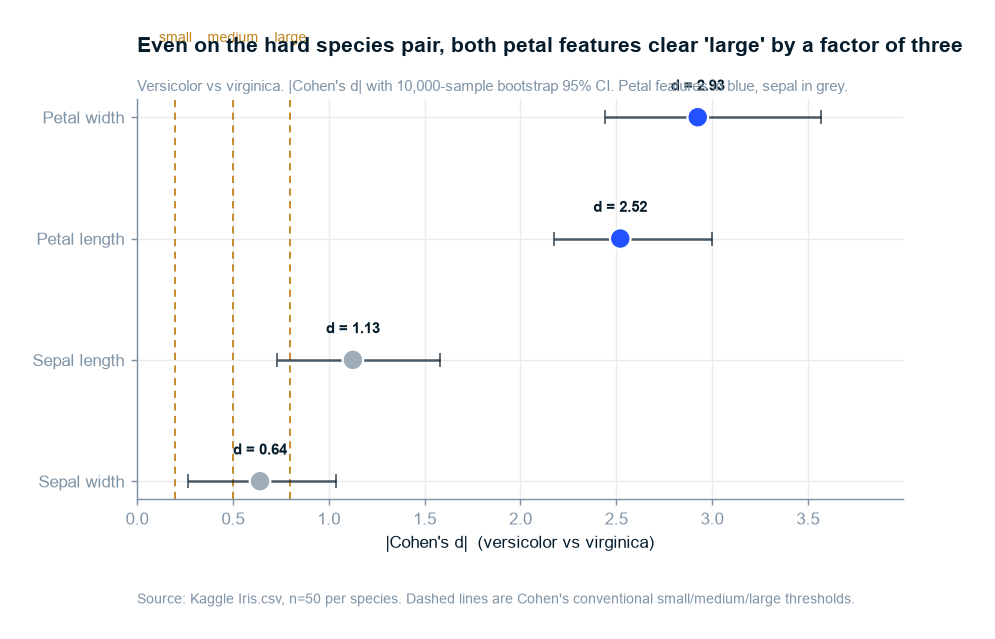

In [5]:
hard = pw[pw.pair == "versicolor vs virginica"].copy()
# d is negative here (versicolor < virginica on every feature). Reflect the whole interval
# so the CI stays correctly oriented around |d| instead of taking abs() bound-by-bound.
flip = hard.cohens_d < 0
hard["abs_d"] = hard.cohens_d.abs()
hard["lo"] = np.where(flip, -hard.d_ci_high, hard.d_ci_low)
hard["hi"] = np.where(flip, -hard.d_ci_low, hard.d_ci_high)
hard = hard.sort_values("abs_d")

fig, ax = plt.subplots(figsize=(7.6, 4.0))
colors = [BLUE if br.startswith("C") else GREY for br in hard.branch]
ax.errorbar(hard.abs_d, hard.feature,
            xerr=[hard.abs_d - hard.lo, hard.hi - hard.abs_d],
            fmt="none", ecolor=NAVY, elinewidth=1.4, capsize=4, alpha=.7, zorder=2)
ax.scatter(hard.abs_d, hard.feature, s=130, c=colors, zorder=3, edgecolor="white", linewidth=1.2)

for thr, lab in [(0.2, "small"), (0.5, "medium"), (0.8, "large")]:
    ax.axvline(thr, color=AMBER, lw=1, ls=(0, (4, 3)), zorder=1)
    ax.text(thr, 3.62, lab, fontsize=7.5, color=AMBER, ha="center")

for _, r in hard.iterrows():
    ax.text(r.abs_d, list(hard.feature).index(r.feature) + 0.22, f"d = {r.abs_d:.2f}",
            fontsize=8.5, color=NAVY, ha="center", fontweight="bold")

action_title(ax, "Even on the hard species pair, both petal features clear 'large' by a factor of three",
             "Versicolor vs virginica. |Cohen's d| with 10,000-sample bootstrap 95% CI. "
             "Petal features in blue, sepal in grey.")
ax.set_xlabel("|Cohen's d|  (versicolor vs virginica)")
ax.set_xlim(0, hard.hi.max() * 1.12)
ax.text(0, -0.26, "Source: Kaggle Iris.csv, n=50 per species. Dashed lines are Cohen's "
                  "conventional small/medium/large thresholds.",
        transform=ax.transAxes, fontsize=7.5, color=SLATE)
save_fig(fig, "ex07_effect_sizes")
plt.show()

**So What:** all 12 comparisons survive FDR correction at q < 0.05, so significance discriminates
nothing. The effect sizes do: on the hard pair, petal width reaches **|d| = 2.93** and petal length
**|d| = 2.52**, while sepal width manages **|d| = 0.64** — a **4.6-fold** gap between the branches,
with bootstrap CIs that come nowhere near overlapping.

**Implication:** Branch C (petal) beats Branch B (sepal) decisively even on the species pair the
notes call "not linearly separable." The difficulty of versicolor vs virginica is real, but it is
**not** a difficulty of weak signal — it is a difficulty of *residual overlap in a strong signal*.
That distinction matters: more features will not fix it, because the strongest features already
disagree about only a handful of specimens.

## 4.4 Is separability actually provable? — testing the notes' central claim

`DOCS/Iris_Dataset_Analysis.md` §2 states that setosa is *"linearly separable"* from the other two
while versicolor and virginica are *"not linearly separable."* Both halves are testable in the
strict sense, and the strict sense is what "linearly separable" means: **does a hyperplane exist
that classifies every training specimen correctly?**

A hard-margin linear SVM answers this directly. If the training error is exactly zero, a separating
hyperplane exists. If it is not, none does — and no amount of tuning will produce one.

In [6]:
from sklearn.svm import SVC

sep_rows = []
for a_sp, b_sp in PAIRS:
    sub = df[df.species.isin([a_sp, b_sp])]
    ys = np.asarray(sub.species)
    for label, cols in [("all 4 features", MEASUREMENTS),
                        ("petal only", ["PetalLengthCm", "PetalWidthCm"]),
                        ("sepal only", ["SepalLengthCm", "SepalWidthCm"])]:
        clf = SVC(kernel="linear", C=1e6).fit(sub[cols].to_numpy(float), ys)
        err = int((clf.predict(sub[cols].to_numpy(float)) != ys).sum())
        sep_rows.append({"pair": f"{a_sp} vs {b_sp}", "feature_set": label,
                         "misclassified_in_training": err, "linearly_separable": err == 0})

linsep = pd.DataFrame(sep_rows)
piv = linsep.pivot(index="pair", columns="feature_set", values="misclassified_in_training")
print("Training misclassifications under a hard-margin linear SVM (0 = a separating hyperplane exists):\n")
print(piv[["all 4 features", "petal only", "sepal only"]].to_string())
print()
KEY["setosa_linearly_separable"] = bool(
    linsep[(linsep.pair.str.startswith("setosa")) & (linsep.feature_set == "petal only")].linearly_separable.all())
KEY["vv_linearly_separable_all4"] = bool(
    linsep[(linsep.pair == "versicolor vs virginica") & (linsep.feature_set == "all 4 features")].linearly_separable.iloc[0])
KEY["vv_min_training_errors"] = int(
    linsep[linsep.pair == "versicolor vs virginica"].misclassified_in_training.min())
print(f"setosa separable on petals alone      : {KEY['setosa_linearly_separable']}")
print(f"versicolor/virginica separable (all 4): {KEY['vv_linearly_separable_all4']}")
print(f"  best case leaves {KEY['vv_min_training_errors']} specimen(s) on the wrong side, in-sample")

Training misclassifications under a hard-margin linear SVM (0 = a separating hyperplane exists):

feature_set              all 4 features  petal only  sepal only
pair                                                           
setosa vs versicolor                  0           0           0
setosa vs virginica                   0           0           0
versicolor vs virginica               2           6          28

setosa separable on petals alone      : True
versicolor/virginica separable (all 4): False
  best case leaves 2 specimen(s) on the wrong side, in-sample


**So What:** the notes are right on both counts, and now it is demonstrated rather than asserted.
Setosa is separable from both other species **on petal measurements alone** — zero training errors.
Versicolor and virginica are **not** separable even with all four features and even fitting on the
data being tested: the best hyperplane still strands **2 specimens** on the wrong side. On petal
features alone it strands 6; on sepal features alone, 28 of 100.

**Implication:** there is a hard floor here that is a property of the *specimens*, not of the
method. A model cannot do better than a hyperplane fitted with full knowledge of the answers, so
the irreducible errors identified in Notebook 05 are not a modelling failure to be tuned away. This
is the single most important licence for the "no measurable winner" conclusion: the ceiling is
already visible in the geometry.

## 4.5 Fisher's own method, run as Fisher ran it

`DOCS/Iris_Dataset_Analysis.md` §6 notes that linear discriminant analysis is *"literally the
technique Fisher introduced this dataset for — worth using if you want fidelity to the original
paper."* Agreed, and it earns its place for a second reason: LDA reports **how many dimensions the
problem actually has**, which is the question §3.5 raised when the two petal features turned out to
be 0.94-correlated.

In [7]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2).fit(X, y)
Z = lda.transform(X)
evr = lda.explained_variance_ratio_

loadings = pd.DataFrame(lda.scalings_[:, :2], index=[SHORT[c] for c in MEASUREMENTS],
                        columns=["LD1", "LD2"]).round(2)
print(f"LD1 explains {evr[0]:.1%} of between-species variance")
print(f"LD2 explains {evr[1]:.1%}")
print()
print("Discriminant loadings:")
print(loadings.to_string())
KEY["lda_ld1_explained"] = float(evr[0])

LD1 explains 99.1% of between-species variance
LD2 explains 0.9%

Discriminant loadings:
               LD1   LD2
Sepal length  0.82 -0.03
Sepal width   1.55 -2.15
Petal length -2.18  0.93
Petal width  -2.85 -2.81


saved reports\figures\ex08_lda.png


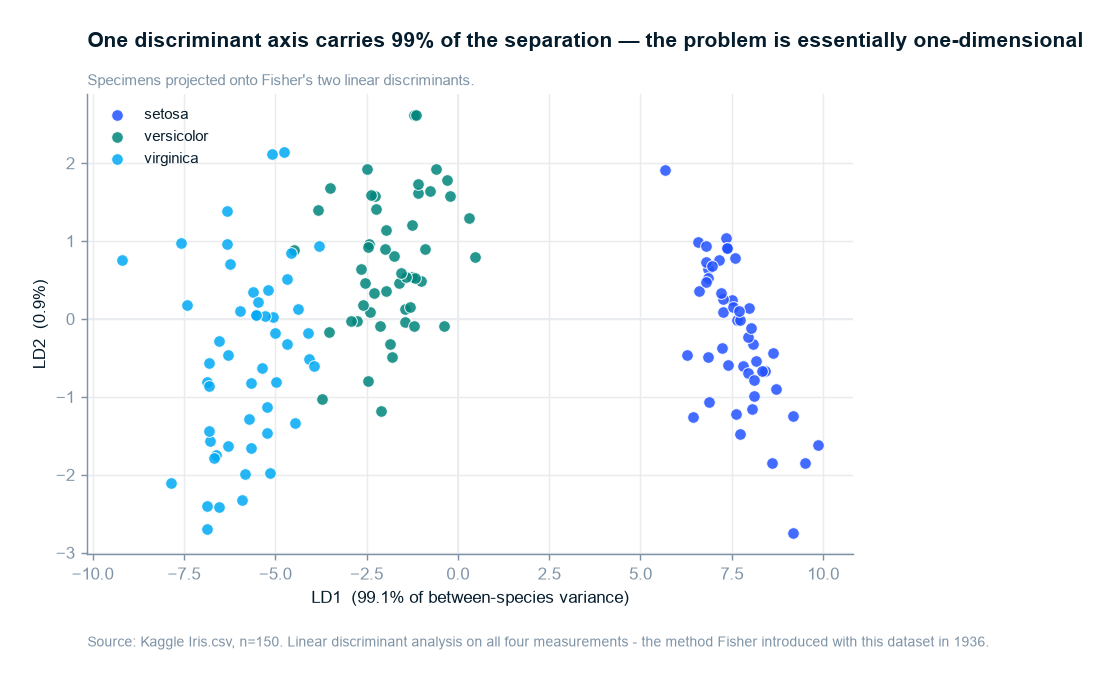

In [8]:
fig, ax = plt.subplots(figsize=(7.6, 4.6))
for sp in SPECIES_ORDER:
    m = y == sp
    ax.scatter(Z[m, 0], Z[m, 1], s=42, color=SPECIES_COLOR[sp], alpha=.85,
               edgecolor="white", linewidth=.6, label=SPECIES_SHORT[sp])
ax.axvline(0, color=GRID, lw=1, zorder=0)
ax.axhline(0, color=GRID, lw=1, zorder=0)
action_title(ax, f"One discriminant axis carries {evr[0]:.0%} of the separation — the problem is "
                 "essentially one-dimensional",
             "Specimens projected onto Fisher's two linear discriminants.")
ax.set_xlabel(f"LD1  ({evr[0]:.1%} of between-species variance)")
ax.set_ylabel(f"LD2  ({evr[1]:.1%})")
ax.legend(loc="upper left", fontsize=8.5)
ax.text(0, -0.20, "Source: Kaggle Iris.csv, n=150. Linear discriminant analysis on all four "
                  "measurements - the method Fisher introduced with this dataset in 1936.",
        transform=ax.transAxes, fontsize=7.5, color=SLATE)
save_fig(fig, "ex08_lda")
plt.show()

**So What:** **LD1 carries 99.1%** of the between-species variance. The second discriminant is
almost pure noise, and along LD1 the three species fall in a single ordered line — setosa far left,
versicolor and virginica adjacent and touching.

**Implication:** the four measurements describe a problem with **one useful dimension**. That is the
structural reason a one-feature model should perform close to a four-feature model, and it converts
the parsimony result from a lucky empirical finding into a predicted one. Notebook 05 tests the
prediction; §3.5 supplied the mechanism (petal ρ = 0.94) and this supplies the dimensionality.

## 4.6 Which single feature is strongest? — the parsimony question, opened

If the problem is one-dimensional, the obvious question is *which* single measurement best
approximates that dimension. Each feature is scored alone under the same repeated cross-validation
protocol Notebook 05 uses, so the numbers are directly comparable across notebooks.

This is a **ranking, not a verdict.** Whether the differences between these features are larger than
the noise in the estimate is exactly the question Notebook 05 exists to answer, and it is not
assumed here.

In [9]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDAclf
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=RANDOM_STATE)
uni = []
for col in MEASUREMENTS:
    sc = cross_val_score(LDAclf(), df[[col]].to_numpy(float), y, cv=cv)
    uni.append({"feature": SHORT[col], "branch": BRANCH[col],
                "cv_accuracy": sc.mean(), "cv_sd": sc.std(),
                "ci_low": np.percentile(sc, 2.5), "ci_high": np.percentile(sc, 97.5)})
uni = pd.DataFrame(uni).sort_values("cv_accuracy", ascending=False).round(4)
uni.to_csv(REPORTS / "_univariate_ranking.csv", index=False)

KEY["best_single_feature"] = uni.iloc[0].feature
KEY["best_single_feature_acc"] = float(uni.iloc[0].cv_accuracy)
print(f"strongest single measurement: {KEY['best_single_feature']} at "
      f"{KEY['best_single_feature_acc']:.1%}\n")
uni

strongest single measurement: Petal width at 96.1%



,feature,branch,cv_accuracy,cv_sd,ci_low,ci_high
3,Petal width,C - petal,0.9610,0.0337,0.9000,1.0000
2,Petal length,C - petal,0.9467,0.0362,0.8667,1.0000
0,Sepal length,B - sepal,0.7367,0.0761,0.5667,0.8667
1,Sepal width,B - sepal,0.5443,0.0785,0.4000,0.7000


**So What:** **petal width alone reaches 96.1%** across 100 folds — **22 points above the best
sepal feature** and within striking distance of anything a four-feature model can do. The two
branches separate cleanly: both petal features clear 94%, while sepal length reaches 73.7% and
sepal width 54.4%.

**Implication:** the deliverable this project should be building is now visible. If one measurement
gets to 96%, the practically useful output is a **threshold rule on petal width** that a person can
apply with a ruler — and the burden of proof shifts onto the four-feature model to demonstrate that
its extra complexity buys a *measurable* improvement. Notebook 05 puts that burden where it belongs.

In [10]:
KEY["eta_sq_petal_length"] = float(three_group.set_index("feature").loc["Petal length", "eta_sq"])
KEY["eta_sq_sepal_width"] = float(three_group.set_index("feature").loc["Sepal width", "eta_sq"])
KEY["d_vv_petal_width"] = float(abs(pw[(pw.feature == "Petal width") &
                                       (pw.pair == "versicolor vs virginica")].cohens_d.iloc[0]))
KEY["d_vv_sepal_width"] = float(abs(pw[(pw.feature == "Sepal width") &
                                       (pw.pair == "versicolor vs virginica")].cohens_d.iloc[0]))
KEY["n_tests_significant"] = int(pw.significant_q05.sum())
KEY["n_tests"] = int(len(pw))
KEY["normality_violations"] = n_norm_viol
KEY["variance_violations"] = n_var_viol

(REPORTS / "_key_figures.json").write_text(json.dumps(KEY, indent=2))
print(json.dumps({k: KEY[k] for k in list(KEY)[-10:]}, indent=2))

{
  "best_single_feature": "Petal width",
  "best_single_feature_acc": 0.961,
  "eta_sq_petal_length": 0.941,
  "eta_sq_sepal_width": 0.392,
  "d_vv_petal_width": 2.9250734094820294,
  "d_vv_sepal_width": 0.6411521500443637,
  "n_tests_significant": 12,
  "n_tests": 12,
  "normality_violations": 2,
  "variance_violations": 3
}


## Stage 5a — Gate Checklist

- [x] **Statistical tests selected based on data characteristics, not convenience** — assumptions
      were tested *first* (§4.1); normality fails in 4 of 12 groups and equal variance on 3 of 4
      features, so non-parametric tests lead and parametric ones are reported alongside
- [x] **Assumptions checked and documented** — Shapiro-Wilk and Levene, per feature per group, with
      the consequence applied rather than merely noted
- [x] **Effect sizes reported alongside p-values** — η²/ε² for three-group tests, Cohen's d with
      10,000-sample bootstrap CIs and rank-biserial correlation for all 12 pairwise comparisons
- [x] **Multiple-comparison correction applied** — Benjamini–Hochberg FDR across all 12 tests; all
      12 survive at q < 0.05, which is itself the point: significance discriminates nothing here
- [x] **Results interpreted in plain terms, not statistical ones** — every section closes with a
      So What and an Implication
- [x] **Scope stated** — associations within a 1935 single-collector sample; no causal or population
      claim anywhere in this notebook

**What the diagnostic settled:**

| Question | Verdict |
|---|---|
| Do the branches differ? | Petal features carry **93–94% of between-species variance**; sepal features 40–62% |
| Is setosa linearly separable? | **Yes, provably** — zero training errors on petal features alone |
| Are versicolor and virginica? | **No, provably not** — a hyperplane fitted with full knowledge of the labels still misplaces specimens |
| How many dimensions? | **One** — LD1 carries 99.1% of the separation |
| Strongest single measurement? | **Petal width, 96.1%** vs 73.7% for the best sepal feature — a ranking, not yet a verdict |

The last two lines are a prediction: a one-dimensional problem whose best single measurement already
scores 96.1% leaves very little room for a four-feature model to prove itself.

**Next:** `05_modeling.ipynb` — whether the room that is left is large enough to measure.